# Final Evaluation and High Risk Customer Profiling
Group 2026-DS-77
Responsible member: IT24103677 — Group Leader

## Purpose
Evaluate the saved model on the reserved test set using the frozen
preprocessing, model settings and threshold. Then describe the customers
flagged by this procedure and develop a qualified stakeholder recommendation.

## Evaluation boundary
The model and threshold were selected using development data.
Test results will not be used to change preprocessing, model settings,
feature choices or the threshold.

Development model selection, final fitting and reload checks are complete. Reserved-test evaluation and descriptive high-risk profiling are also complete, with results and reproducibility details recorded below. The stakeholder recommendation awaits group review.

In [1]:
#Mount Drive and locate the required files

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn"
)

MODELS_DIR = PROJECT_DIR / "models"
SPLITS_DIR = PROJECT_DIR / "data" / "splits"
SRC_DIR = PROJECT_DIR / "src"

MODEL_PATH = MODELS_DIR / "selected_churn_pipeline.joblib"
FREEZE_PATH = MODELS_DIR / "frozen_model_procedure.json"
HANDOVER_PATH = MODELS_DIR / "model_handover_record.json"

MODULE_PATH = SRC_DIR / "telco_preprocessing.py"
DEV_PATH = SPLITS_DIR / "development.csv"
TEST_PATH = SPLITS_DIR / "test.csv"
SPLIT_RECORD_PATH = SPLITS_DIR / "split_record.json"
SPLIT_MANIFEST_PATH = SPLITS_DIR / "split_manifest.csv"

required_files = [
    MODEL_PATH,
    FREEZE_PATH,
    HANDOVER_PATH,
    MODULE_PATH,
    DEV_PATH,
    TEST_PATH,
    SPLIT_RECORD_PATH,
    SPLIT_MANIFEST_PATH,
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(f"Required file missing: {path}")

# Checking that test.csv exists does not load its contents.
print("All required handover and split files found.")
print("Reserved test data have not been loaded.")

Mounted at /content/drive
All required handover and split files found.
Reserved test data have not been loaded.


In [2]:
#Verify that the handed-over files match their records

import hashlib
import json


def file_sha256(path):
    """Identify file contents using a SHA-256 fingerprint."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


frozen = json.loads(FREEZE_PATH.read_text(encoding="utf-8"))
handover = json.loads(HANDOVER_PATH.read_text(encoding="utf-8"))

# Verify the saved model and frozen procedure before using either.
assert file_sha256(MODEL_PATH) == handover["model_sha256"], (
    "The model differs from the handover record. Stop and review."
)

assert (
    file_sha256(FREEZE_PATH)
    == handover["frozen_procedure_sha256"]
), "The frozen procedure differs from the handover record."

# Confirm that both records refer to the same preprocessing module.
module_hash = file_sha256(MODULE_PATH)

assert module_hash == handover["preprocessing_module_sha256"]
assert module_hash == frozen["preprocessing_module_sha256"]

# Confirm that the development file remains unchanged.
# This reads file bytes for a fingerprint, not a new analysis.
development_hash = file_sha256(DEV_PATH)

assert development_hash == handover["development_sha256"]
assert development_hash == frozen["development_sha256"]

assert handover["responsible_member"] == "IT24102789"
assert handover["receiving_member"] == "IT24103677"

assert frozen["selected_model"] == "Random forest"
assert frozen["positive_class"] == 1
assert frozen["flag_rule"] == "score >= threshold"

print("Model, frozen procedure, preprocessing and development hashes match.")
print("Selected model:", frozen["selected_model"])
print("Frozen threshold:", repr(frozen["threshold"]))
print("Reserved test data have not been loaded.")

Model, frozen procedure, preprocessing and development hashes match.
Selected model: Random forest
Frozen threshold: 0.319015704046037
Reserved test data have not been loaded.


In [3]:
#Check the environment and inspect the split-record structure
#This lets us write the next integrity checks against your actual saved record format, without guessing its field names.

import platform
import sys

import joblib
import numpy as np
import pandas as pd
import sklearn

current_versions = {
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
}

version_rows = []

for key, current in current_versions.items():
    recorded = handover.get(key, frozen.get(key))

    version_rows.append({
        "Component": key.replace("_version", ""),
        "Recorded": recorded,
        "Current": current,
        "Matches": recorded == current if recorded is not None else False,
    })

version_check = pd.DataFrame(version_rows)
display(version_check)

# Inspect metadata only. Do not load development.csv or test.csv here.
split_record = json.loads(
    SPLIT_RECORD_PATH.read_text(encoding="utf-8")
)

print("\nOriginal split record:")
print(json.dumps(split_record, indent=2))

print("\nOriginal split manifest column names:")
print(pd.read_csv(SPLIT_MANIFEST_PATH, nrows=0).columns.tolist())

print("\nReserved test data have not been loaded.")

,Component,Recorded,Current,Matches
0,python,3.13.15,3.13.16,False
1,pandas,2.2.3,2.2.3,True
2,numpy,2.1.3,2.1.3,True
3,scikit_learn,1.6.1,1.6.1,True
4,joblib,1.6.0,1.6.0,True



Original split record:
{
  "created_at_utc": "2026-09-22T23:48:12.657986+00:00",
  "source_filename": "WA_Fn-UseC_-Telco-Customer-Churn.csv",
  "source_sha256": "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a",
  "random_seed": 42,
  "test_size": 0.2,
  "stratified_by": "Churn",
  "positive_class": "Yes",
  "python_version": "3.13.15",
  "pandas_version": "2.2.3",
  "sklearn_version": "1.6.1",
  "prior_exposure": "Whole-file descriptive summaries were examined before adopting this protocol."
}

Original split manifest column names:
['customerID', 'split']

Reserved test data have not been loaded.


In [4]:
#Your original split record contains the source dataset’s hash, not a separate test-file hash. We’ll therefore check test membership against the saved manifest and verify that its records match the unchanged source dataset.
#Verify the reserved test records
# Load the original source only to verify file identity and record integrity.
# Do not use it for new exploratory analysis or modelling decisions.
SOURCE_PATH = (
    PROJECT_DIR / "data" / "raw" / split_record["source_filename"]
)

assert SOURCE_PATH.is_file(), "Original source CSV is missing."
assert file_sha256(SOURCE_PATH) == split_record["source_sha256"], (
    "The source CSV differs from the original recorded file."
)

# Use the same ID type in every file.
read_options = {"dtype": {"customerID": "string"}}

source = pd.read_csv(SOURCE_PATH, **read_options)
dev_check = pd.read_csv(DEV_PATH, **read_options)
test = pd.read_csv(TEST_PATH, **read_options)
manifest = pd.read_csv(SPLIT_MANIFEST_PATH, **read_options)

for name, frame in [
    ("Source", source),
    ("Development", dev_check),
    ("Test", test),
    ("Manifest", manifest),
]:
    assert frame["customerID"].notna().all(), f"{name}: missing ID."
    assert frame["customerID"].is_unique, f"{name}: duplicate IDs."

assert source.shape == (7043, 21)
assert dev_check.shape == (5634, 21)
assert test.shape == (1409, 21)
assert manifest["split"].notna().all()

source_ids = set(source["customerID"])
dev_ids = set(dev_check["customerID"])
test_ids = set(test["customerID"])

assert dev_ids.isdisjoint(test_ids), "Development/test overlap detected."
assert dev_ids | test_ids == source_ids
assert set(manifest["customerID"]) == source_ids

# Match manifest groups by their customer IDs rather than assuming
# whether the labels were written as "dev", "development", etc.
manifest_groups = {
    str(label): set(group["customerID"])
    for label, group in manifest.groupby("split")
}

assert len(manifest_groups) == 2, "Expected two recorded split groups."

dev_labels = [
    label for label, ids in manifest_groups.items()
    if ids == dev_ids
]
test_labels = [
    label for label, ids in manifest_groups.items()
    if ids == test_ids
]

assert len(dev_labels) == 1, "Development membership does not match manifest."
assert len(test_labels) == 1, "Test membership does not match manifest."
assert dev_labels[0] != test_labels[0]

# Check that saved split values match the source records.
# TotalCharges is compared numerically because blank values may have
# been saved as missing values during the original split preparation.
def canonical_records(frame):
    # Work on a copy without changing the original data.
    result = frame.copy()

    # Treat empty or space-only TotalCharges values as missing.
    # Unexpected non-numeric text will still raise an error.
    result["TotalCharges"] = pd.to_numeric(
        result["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
        errors="raise",
    )

    # Arrange records and columns consistently for comparison.
    return (
        result.set_index("customerID")
        .sort_index()
        .sort_index(axis=1)
    )

source_records = canonical_records(source)

for name, frame in [("Development", dev_check), ("Test", test)]:
    actual = canonical_records(frame)
    expected = source_records.loc[actual.index]

    pd.testing.assert_frame_equal(
        actual,
        expected,
        check_dtype=False,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12,
        obj=f"{name} records compared with source",
    )

print("Source fingerprint verified.")
print("Development and test membership match the original manifest.")
print("No development/test customer overlap.")
print("Saved split records match the original source.")
print("Reserved test records:", len(test))


Source fingerprint verified.
Development and test membership match the original manifest.
No development/test customer overlap.
Saved split records match the original source.
Reserved test records: 1409


In [5]:
#Load the saved pipeline and generate test scores

import importlib

# Make the custom preprocessing function available before loading joblib.
src_location = str(SRC_DIR)
if src_location not in sys.path:
    sys.path.insert(0, src_location)

importlib.invalidate_caches()

import telco_preprocessing as telco_prep
telco_prep = importlib.reload(telco_prep)

assert Path(telco_prep.__file__).resolve() == MODULE_PATH.resolve()
assert file_sha256(MODULE_PATH) == frozen["preprocessing_module_sha256"]

# Load the group's verified fitted artifact.
# Do not fit this pipeline again.
evaluation_pipeline = joblib.load(MODEL_PATH)

assert (
    evaluation_pipeline.named_steps["model"].get_params(deep=False)
    == frozen["complete_estimator_settings"]
)

test_customer_ids = test["customerID"].copy()

assert test["Churn"].notna().all()
assert set(test["Churn"].unique()) == {"No", "Yes"}

y_test = test["Churn"].map({"No": 0, "Yes": 1}).astype("int64")

predictor_columns = frozen["predictor_columns"]

assert len(predictor_columns) == 19
assert set(test.columns) == set(
    predictor_columns + ["customerID", "Churn"]
)

# Preserve the frozen predictor order and pass original inputs.
# The fitted pipeline handles parsing, imputation and encoding.
X_test = test.loc[:, predictor_columns].copy()

classes = evaluation_pipeline.named_steps["model"].classes_
np.testing.assert_array_equal(classes, np.array([0, 1]))

positive_column = int(np.flatnonzero(classes == 1)[0])

test_scores = evaluation_pipeline.predict_proba(
    X_test
)[:, positive_column]

assert len(test_scores) == len(test)
assert np.isfinite(test_scores).all()
assert ((test_scores >= 0) & (test_scores <= 1)).all()

# Read the full-precision threshold from the frozen procedure.
threshold = float(frozen["threshold"])
test_flags = (test_scores >= threshold).astype(int)

print("Saved pipeline applied without fitting or tuning.")
print("Test customers scored:", len(test_scores))
print("Frozen threshold applied:", repr(threshold))

Saved pipeline applied without fitting or tuning.
Test customers scored: 1409
Frozen threshold applied: 0.319015704046037


In [6]:
#Calculate the final test metrics

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve,
)

# AP uses continuous scores; operating metrics use frozen-threshold flags.
test_ap = average_precision_score(y_test, test_scores)
test_precision = precision_score(y_test, test_flags, zero_division=0)
test_recall = recall_score(y_test, test_flags, zero_division=0)
test_f1 = f1_score(y_test, test_flags, zero_division=0)

test_cm = confusion_matrix(y_test, test_flags, labels=[0, 1])
tn, fp, fn, tp = test_cm.ravel()

final_test_summary = pd.DataFrame([{
    "Model": frozen["selected_model"],
    "Test records": len(test),
    "Recorded churners": int(y_test.sum()),
    "Threshold": threshold,
    "Test AP": test_ap,
    "Test precision": test_precision,
    "Test recall": test_recall,
    "Test F1": test_f1,
    "Flagged customers": int(test_flags.sum()),
    "Flagged percentage": 100 * test_flags.mean(),
    "True positives": int(tp),
    "False positives": int(fp),
    "False negatives": int(fn),
    "True negatives": int(tn),
}])

display(final_test_summary.round(4))

print("\nConfusion matrix: rows = actual, columns = predicted")
display(pd.DataFrame(
    test_cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"],
))

# Preserve customer-level results for later export and profiling.
test_predictions = pd.DataFrame({
    "customerID": test_customer_ids.to_numpy(),
    "actual_churn": y_test.to_numpy(),
    "churn_score": test_scores,
    "high_risk_flag": test_flags,
})

# Calculate curve coordinates for the next plotting step.
# These will describe performance, not select a new threshold.
test_curve_precision, test_curve_recall, test_curve_thresholds = (
    precision_recall_curve(y_test, test_scores)
)

print("\nFinal test metrics calculated using the frozen procedure.")
print("No model settings or threshold were changed.")

,Model,Test records,Recorded churners,Threshold,Test AP,Test precision,Test recall,Test F1,Flagged customers,Flagged percentage,True positives,False positives,False negatives,True negatives
0,Random forest,1409,374,0.319,0.6565,0.5491,0.762,0.6383,519,36.8346,285,234,89,801



Confusion matrix: rows = actual, columns = predicted


,Predicted No,Predicted Yes
Actual No,801,234
Actual Yes,89,285



Final test metrics calculated using the frozen procedure.
No model settings or threshold were changed.


In [7]:
#Save the evaluation tables

# Keep final evaluation outputs separate from development comparisons.
EVALUATION_DIR = PROJECT_DIR / "outputs" / "tables" / "final_evaluation"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

# Preserve full precision in saved files.
final_test_summary.to_csv(
    EVALUATION_DIR / "final_test_summary.csv",
    index=False,
)

test_predictions.to_csv(
    EVALUATION_DIR / "final_test_predictions.csv",
    index=False,
)

confusion_table = pd.DataFrame(
    test_cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"],
)
confusion_table.index.name = "Actual class"

confusion_table.to_csv(
    EVALUATION_DIR / "final_test_confusion_matrix.csv"
)

# The final precision–recall point has no corresponding threshold.
curve_table = pd.DataFrame({
    "Precision": test_curve_precision,
    "Recall": test_curve_recall,
    "Threshold": np.append(test_curve_thresholds, np.nan),
})

curve_table.to_csv(
    EVALUATION_DIR / "final_test_precision_recall_curve.csv",
    index=False,
)

print("Saved final test summary, predictions, confusion matrix and PR curve.")
print("Location:", EVALUATION_DIR)

Saved final test summary, predictions, confusion matrix and PR curve.
Location: /content/drive/MyDrive/ML 2026-DS-77 Telco Customer Churn/outputs/tables/final_evaluation


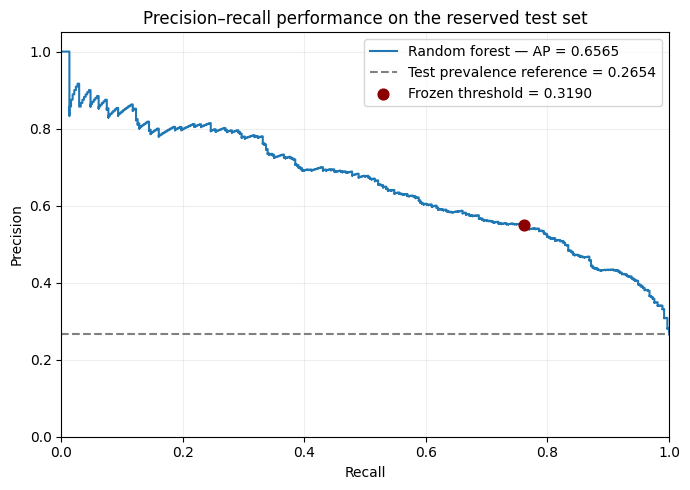

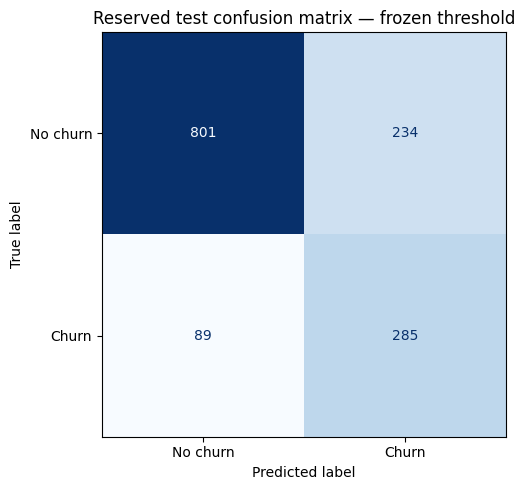

Both final evaluation figures saved.


In [8]:
#Create and save the figures

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

EVALUATION_FIGURES_DIR = (
    PROJECT_DIR / "outputs" / "figures" / "final_evaluation"
)
EVALUATION_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plot ranking performance and the already-frozen operating point.
fig, ax = plt.subplots(figsize=(7, 5))

ax.step(
    test_curve_recall,
    test_curve_precision,
    where="post",
    label=f"Random forest — AP = {test_ap:.4f}",
)

# A constant-score reference has AP equal to test churn prevalence.
# This is a descriptive reference, not a newly trained comparator.
ax.axhline(
    y_test.mean(),
    color="grey",
    linestyle="--",
    label=f"Test prevalence reference = {y_test.mean():.4f}",
)

ax.scatter(
    test_recall,
    test_precision,
    color="darkred",
    s=60,
    zorder=3,
    label=f"Frozen threshold = {threshold:.4f}",
)

ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title="Precision–recall performance on the reserved test set",
    xlim=(0, 1),
    ylim=(0, 1.05),
)
ax.legend(loc="best")
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    EVALUATION_FIGURES_DIR / "final_test_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Display the actual error counts at the frozen threshold.
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["No churn", "Churn"],
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("Reserved test confusion matrix — frozen threshold")

fig.tight_layout()
fig.savefig(
    EVALUATION_FIGURES_DIR / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Both final evaluation figures saved.")

In [9]:
#Record which files produced these results

from datetime import datetime, timezone

# Confirm that the evaluated artifacts have not changed.
assert file_sha256(MODEL_PATH) == handover["model_sha256"]
assert (
    file_sha256(FREEZE_PATH)
    == handover["frozen_procedure_sha256"]
)
assert (
    file_sha256(MODULE_PATH)
    == frozen["preprocessing_module_sha256"]
)

evaluation_record = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "responsible_member": "IT24103677",
    "model_sha256": file_sha256(MODEL_PATH),
    "frozen_procedure_sha256": file_sha256(FREEZE_PATH),
    "preprocessing_module_sha256": file_sha256(MODULE_PATH),
    "test_file_sha256": file_sha256(TEST_PATH),
    "original_split_manifest_sha256": file_sha256(SPLIT_MANIFEST_PATH),
    "original_split_record_sha256": file_sha256(SPLIT_RECORD_PATH),
    "test_records": len(test),
    "threshold": threshold,
    "flag_rule": frozen["flag_rule"],
    "software_versions": current_versions,
    "test_membership_and_source_values_verified": True,
    "evaluation_method": (
        "Saved fitted pipeline applied without fitting; "
        "threshold loaded from frozen procedure."
    ),
    "summary_sha256": file_sha256(
        EVALUATION_DIR / "final_test_summary.csv"
    ),
    "predictions_sha256": file_sha256(
        EVALUATION_DIR / "final_test_predictions.csv"
    ),
}

# This records the current verified evaluation run.
# It does not claim that this timestamp was the first test access.
record_path = EVALUATION_DIR / "final_evaluation_run_record.json"

record_path.write_text(
    json.dumps(evaluation_record, indent=2),
    encoding="utf-8",
)

print("Saved final evaluation run record.")

Saved final evaluation run record.


## High Risk Customer Profiling

We describe customers flagged by the frozen model and threshold, comparing
them with unflagged customers in the reserved test set.

Group membership is determined by the model flag, not the actual Churn label.

This is descriptive analysis after final evaluation. It will not be used
to change features, model settings or the threshold. Differences between
groups do not establish causal effects or model feature importance.

In [10]:
#Join predictions to the original customer attributes

# Join by customerID rather than assuming that row order is identical.
# Keep the original test dataframe unchanged.
profile = test.merge(
    test_predictions[
        ["customerID", "actual_churn", "churn_score", "high_risk_flag"]
    ],
    on="customerID",
    how="left",
    validate="one_to_one",
    indicator=True,
)

assert len(profile) == len(test)
assert profile["_merge"].eq("both").all()
profile = profile.drop(columns="_merge")

# Confirm that predictions remain attached to the correct recorded labels.
expected_labels = profile["Churn"].map({"No": 0, "Yes": 1})
assert expected_labels.eq(profile["actual_churn"]).all()

# Verify that group membership follows the frozen threshold.
expected_flags = (profile["churn_score"] >= threshold).astype(int)
assert expected_flags.eq(profile["high_risk_flag"]).all()

profile["Risk group"] = profile["high_risk_flag"].map({
    0: "Unflagged",
    1: "Flagged",
})

# Parse charges for descriptive summaries, leaving missing values missing.
# Do not replace missing charges with model-imputed values for this profile.
profile["TotalCharges"] = pd.to_numeric(
    profile["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="raise",
)

GROUP_ORDER = ["Unflagged", "Flagged"]

group_summary = (
    profile.groupby("Risk group")
    .agg(
        Customers=("customerID", "size"),
        Recorded_churners=("actual_churn", "sum"),
    )
    .reindex(GROUP_ORDER)
)

group_summary["Recorded_non_churners"] = (
    group_summary["Customers"] - group_summary["Recorded_churners"]
)

group_summary["Recorded_churn_percentage"] = (
    100
    * group_summary["Recorded_churners"]
    / group_summary["Customers"]
)

assert group_summary.loc["Flagged", "Customers"] == int(test_flags.sum())
assert group_summary["Customers"].sum() == len(test)

display(group_summary.round(2))
print("Predictions joined successfully by customerID.")

#“Unflagged” does not mean no risk: that group still contains 89 recorded churners.

,Customers,Recorded_churners,Recorded_non_churners,Recorded_churn_percentage
Risk group,,,,
Unflagged,890,89,801,10.00
Flagged,519,285,234,54.91


Predictions joined successfully by customerID.


In [11]:
#Compare numerical characteristics
#This compares tenure and charges using medians and the middle 50% of values. It also shows how many values are missing.

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

numerical_rows = []

for feature in numerical_features:
    for group_name in GROUP_ORDER:
        values = profile.loc[
            profile["Risk group"].eq(group_name), feature
        ]

        numerical_rows.append({
            "Feature": feature,
            "Risk group": group_name,
            "Customers": len(values),
            "Observed values": int(values.notna().sum()),
            "Missing values": int(values.isna().sum()),
            "Median": values.median(),
            "25th percentile": values.quantile(0.25),
            "75th percentile": values.quantile(0.75),
        })

numerical_profile = pd.DataFrame(numerical_rows)

display(numerical_profile.round(2))

,Feature,Risk group,Customers,Observed values,Missing values,Median,25th percentile,75th percentile
0,tenure,Unflagged,890,890,0,46.50,22.00,63.00
1,tenure,Flagged,519,519,0,8.00,2.00,22.00
2,MonthlyCharges,Unflagged,890,890,0,58.35,20.85,85.66
3,MonthlyCharges,Flagged,519,519,0,78.75,68.60,90.55
4,TotalCharges,Unflagged,890,887,3,1885.15,795.18,4700.52
5,TotalCharges,Flagged,519,519,0,556.35,131.48,1904.75


In [12]:
#Compare categorical characteristics
#This is a focused starting set, not a claim that these are the model’s five most important features.

categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport",
]

categorical_rows = []

for feature in categorical_features:
    assert profile[feature].notna().all(), (
        f"Missing values found in {feature}; review before summarising."
    )

    # Include every observed category, even if absent from one risk group.
    categories = sorted(profile[feature].unique())

    for group_name in GROUP_ORDER:
        group_values = profile.loc[
            profile["Risk group"].eq(group_name), feature
        ]

        counts = group_values.value_counts().reindex(
            categories, fill_value=0
        )

        for category, count in counts.items():
            categorical_rows.append({
                "Feature": feature,
                "Category": category,
                "Risk group": group_name,
                "Customers in category": int(count),
                "Group customers": len(group_values),
                "Percentage within risk group": (
                    100 * count / len(group_values)
                ),
            })

categorical_profile = pd.DataFrame(categorical_rows)

# Within each feature and risk group, category percentages must total 100%.
percentage_totals = categorical_profile.groupby(
    ["Feature", "Risk group"]
)["Percentage within risk group"].sum()

np.testing.assert_allclose(
    percentage_totals.to_numpy(),
    100.0,
)

for feature in categorical_features:
    print(f"\n{feature}")

    comparison = (
        categorical_profile.loc[
            categorical_profile["Feature"].eq(feature)
        ]
        .pivot(
            index="Category",
            columns="Risk group",
            values="Percentage within risk group",
        )
        .reindex(columns=GROUP_ORDER)
    )

    display(comparison.round(2))


Contract


Risk group,Unflagged,Flagged
Category,,
Month-to-month,29.33,98.65
One year,32.92,1.35
Two year,37.75,0.00



InternetService


Risk group,Unflagged,Flagged
Category,,
DSL,41.24,22.54
Fiber optic,25.51,74.37
No,33.26,3.08



PaymentMethod


Risk group,Unflagged,Flagged
Category,,
Bank transfer (automatic),27.08,11.37
Credit card (automatic),27.98,11.56
Electronic check,18.09,60.31
Mailed check,26.85,16.76



OnlineSecurity


Risk group,Unflagged,Flagged
Category,,
No,28.65,85.93
No internet service,33.26,3.08
Yes,38.09,10.98



TechSupport


Risk group,Unflagged,Flagged
Category,,
No,29.44,84.78
No internet service,33.26,3.08
Yes,37.30,12.14


### Interpretation of the high risk customer profile

The frozen procedure flagged 519 of 1,409 reserved-test customers. Among flagged customers, 285 were recorded churners, giving a recorded churn proportion of 54.91%, compared with 10.00% among the 890 unflagged customers. These proportions describe the evaluated sample, not verified future churn probabilities.

Flagged customers had shorter median tenure than unflagged customers (8 versus 46.5 months), higher median MonthlyCharges (78.75 versus 58.35), and lower median observed TotalCharges (556.35 versus 1,885.15). Three TotalCharges values were missing in the unflagged group and were excluded from that descriptive summary.

Month-to-month contracts represented 98.65% of flagged customers, compared with 29.33% of unflagged customers. Fiber-optic internet and electronic-check payment were also more common in the flagged group. OnlineSecurity and TechSupport were recorded as “No” for 85.93% and 84.78% of flagged customers respectively. “No internet service” remains a separate category.

These findings help the retention team understand the composition of the model-generated shortlist. They do not establish which features caused individual predictions, why customers left, or whether changing a contract, payment method or service would prevent churn. The characteristics were summarised separately and should not be presented as one combined customer segment.

The unflagged group still contained 89 recorded churners. No two-year-contract customers were flagged in this test sample, but this does not establish that such customers cannot churn.

Profiling was performed after applying the frozen procedure. No model settings, preprocessing choices or threshold were changed using these findings.

In [13]:
#Save the profiling tables

# Save descriptive results alongside the final evaluation evidence.
# Keep full precision in CSV files; round only for display.
group_summary.to_csv(
    EVALUATION_DIR / "test_profile_group_summary.csv"
)

numerical_profile.to_csv(
    EVALUATION_DIR / "test_profile_numerical.csv",
    index=False,
)

# This retains counts and group denominators as well as percentages.
categorical_profile.to_csv(
    EVALUATION_DIR / "test_profile_categorical.csv",
    index=False,
)

print("Saved all three profiling tables.")

Saved all three profiling tables.


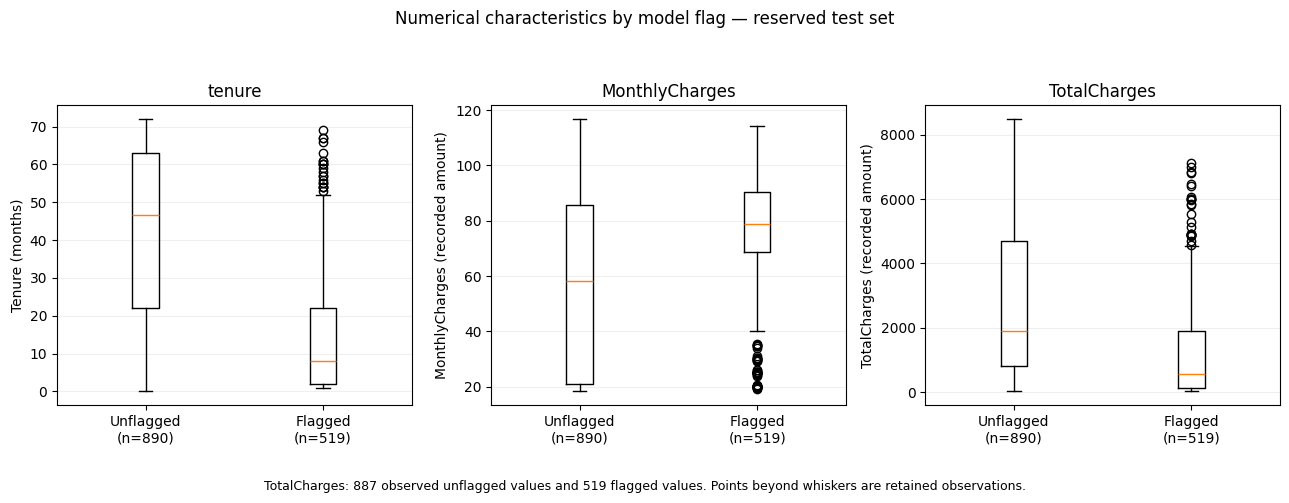

In [14]:
#Plot the numerical profiles
#These plots show distributions, rather than only comparing medians.

import matplotlib.pyplot as plt

group_labels = [
    f"{group}\n(n={int(group_summary.loc[group, 'Customers'])})"
    for group in GROUP_ORDER
]

axis_labels = {
    "tenure": "Tenure (months)",
    "MonthlyCharges": "MonthlyCharges (recorded amount)",
    "TotalCharges": "TotalCharges (recorded amount)",
}

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

for ax, feature in zip(axes, numerical_features):
    # Missing observations are excluded only from this descriptive plot.
    values_by_group = [
        profile.loc[
            profile["Risk group"].eq(group), feature
        ].dropna().to_numpy()
        for group in GROUP_ORDER
    ]

    ax.boxplot(values_by_group)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(group_labels)
    ax.set_title(feature)
    ax.set_ylabel(axis_labels[feature])
    ax.grid(axis="y", alpha=0.2)

fig.suptitle("Numerical characteristics by model flag — reserved test set")

fig.text(
    0.5,
    0.02,
    "TotalCharges: 887 observed unflagged values and 519 flagged values. "
    "Points beyond whiskers are retained observations.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.08, 1, 0.93])

fig.savefig(
    EVALUATION_FIGURES_DIR / "test_profile_numerical.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

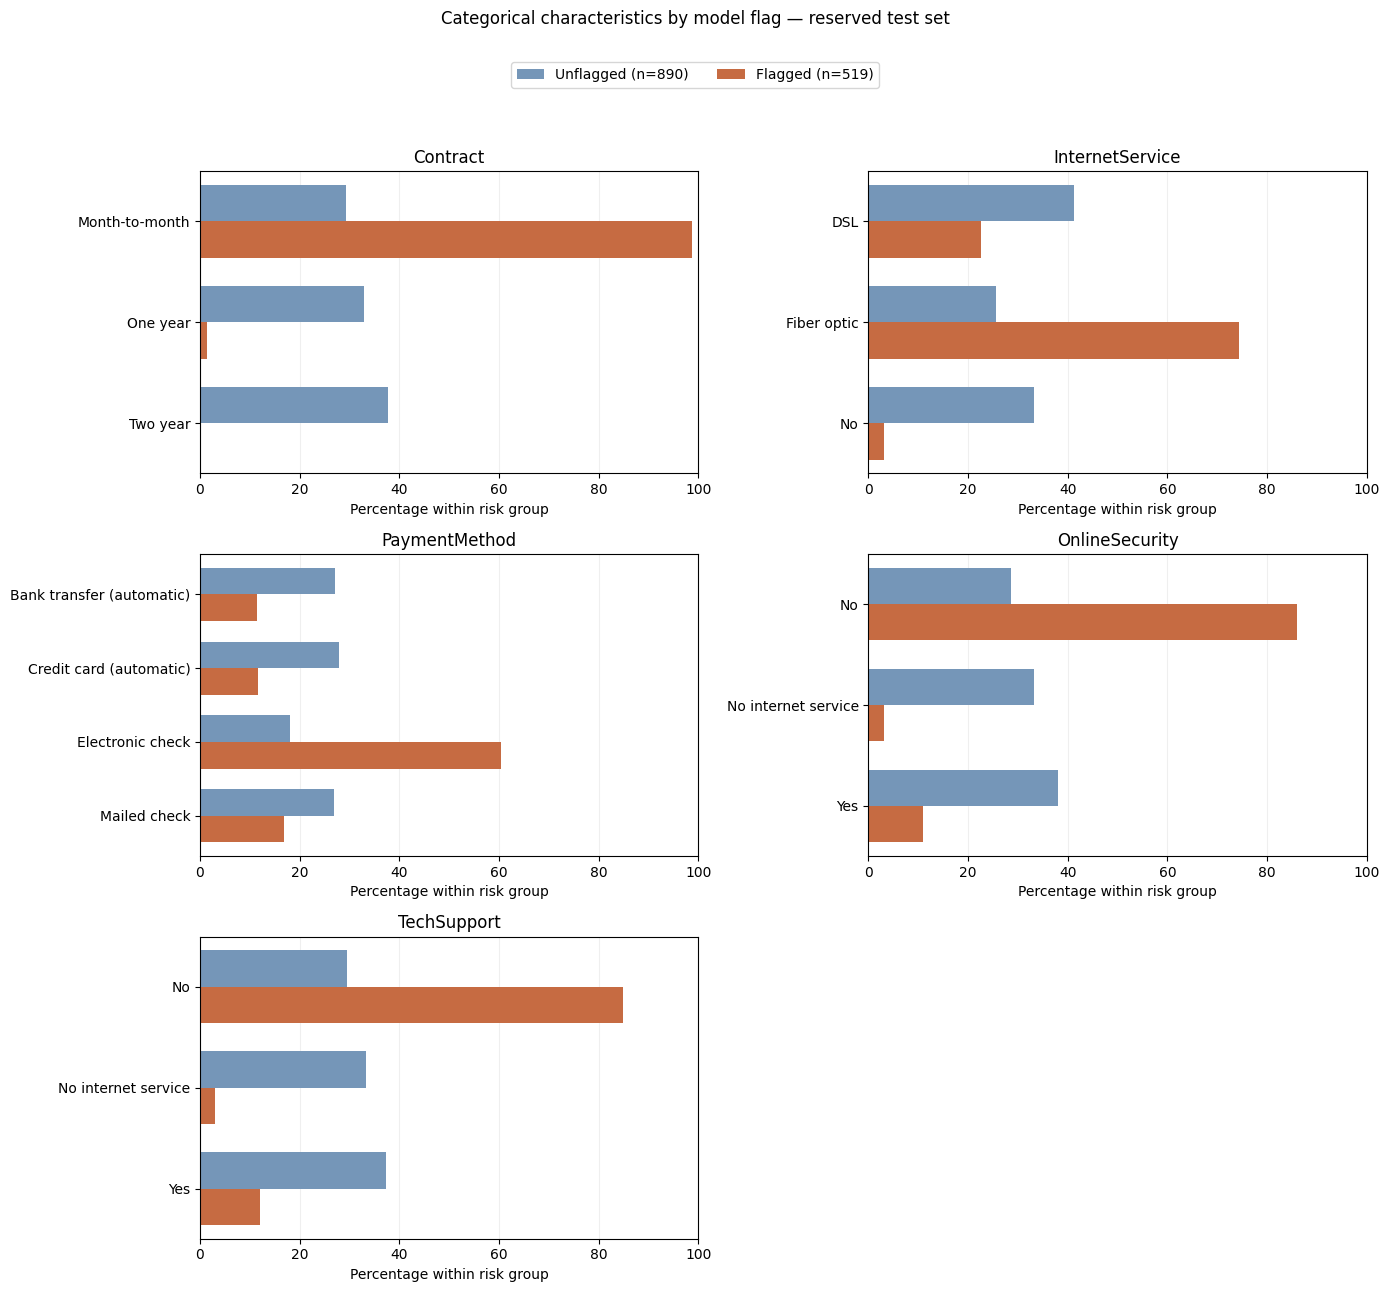

Both profiling figures saved.


In [15]:
#Plot the categorical profiles
#We will show all categories for the five chosen features, including service-absence categories.

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
axes = axes.ravel()

colors = {
    "Unflagged": "#7596B8",
    "Flagged": "#C66B42",
}

for ax, feature in zip(axes, categorical_features):
    comparison = (
        categorical_profile.loc[
            categorical_profile["Feature"].eq(feature)
        ]
        .pivot(
            index="Category",
            columns="Risk group",
            values="Percentage within risk group",
        )
        .reindex(columns=GROUP_ORDER)
    )

    positions = np.arange(len(comparison))
    bar_height = 0.36

    for group_index, group in enumerate(GROUP_ORDER):
        offset = (group_index - 0.5) * bar_height

        ax.barh(
            positions + offset,
            comparison[group].to_numpy(),
            height=bar_height,
            color=colors[group],
            label=(
                f"{group} "
                f"(n={int(group_summary.loc[group, 'Customers'])})"
            ),
        )

    ax.set_yticks(positions)
    ax.set_yticklabels(comparison.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage within risk group")
    ax.set_title(feature)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

# Five features use five panels; hide the unused sixth panel.
axes[-1].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=2,
)

fig.suptitle(
    "Categorical characteristics by model flag — reserved test set",
    y=0.99,
)

fig.tight_layout(rect=[0, 0, 1, 0.92])

fig.savefig(
    EVALUATION_FIGURES_DIR / "test_profile_categorical.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Both profiling figures saved.")

## Stakeholder recommendation

The selected random forest provides evidence that the supplied customer information can help identify recorded churners. On the reserved test set, it achieved average precision of 0.6565. At the frozen threshold of 0.319015704046037, precision was 54.91%, recall was 76.20%, and F1 was 0.6383.

The procedure flagged 519 of 1,409 customers. These included 285 recorded churners and 234 recorded non-churners. It missed 89 recorded churners. The retention team should therefore understand the output as a shortlist requiring review, rather than a definitive identification of who will leave.

We recommend further validation with the provider’s appropriately dated customer data before operational use. Predictor values must be available before the intended prediction period. Contact capacity, intervention costs and expected benefits should then inform the operating policy, followed by a controlled assessment of whether outreach improves retention.

The flagged group was concentrated among customers with shorter tenure and month-to-month contracts. Higher monthly charges, fiber-optic internet and electronic-check payment were also more common in this group. These findings can guide questions for customer research and service review. They do not demonstrate that changing these characteristics would prevent churn.

The random forest’s development AP advantage over logistic regression was small, approximately 0.0055. Logistic regression remains a useful simpler comparator for future validation. The final test assessment evaluated the selected forest; it did not establish that the forest outperforms logistic regression on the test set.

## Limitations and responsible interpretation

- The dataset does not establish that all predictors were recorded before the churn outcome period. The results therefore do not verify future-period forecasting.
- Performance on this supplied dataset does not establish performance for a Sri Lankan provider or another customer population.
- The F1-based threshold is an analytical choice. Its workload and financial suitability have not been established.
- Development results supported model and threshold selection. They are not independent final performance estimates.
- The search covered three supervised model families and a bounded set of configurations. Alternative preprocessing and feature-selection methods were not separately compared.
- Profiling describes model-flagged customers. It does not establish feature importance, individual prediction explanations or causal effects.
- Probability calibration, subgroup fairness and intervention effectiveness were not established. These require further assessment before operational decisions.
- The reserved test has now been evaluated. Changes prompted by these results would require a separately disclosed development and evaluation process.

## Treatment of missing test values

The three missing test-set TotalCharges values were handled within the fitted prediction pipeline using the median learned from development data. All test customers received predictions.

Descriptive profiles retained the original missingness. The unflagged TotalCharges summary therefore used 887 observed values rather than replacing missing amounts with estimates.

In [16]:
#Check the saved output inventory

# Check that all expected evaluation and profiling files exist.
# This checks the output inventory, not predictive correctness.
expected_outputs = [
    EVALUATION_DIR / "final_test_summary.csv",
    EVALUATION_DIR / "final_test_predictions.csv",
    EVALUATION_DIR / "final_test_confusion_matrix.csv",
    EVALUATION_DIR / "final_test_precision_recall_curve.csv",
    EVALUATION_DIR / "final_evaluation_run_record.json",
    EVALUATION_DIR / "test_profile_group_summary.csv",
    EVALUATION_DIR / "test_profile_numerical.csv",
    EVALUATION_DIR / "test_profile_categorical.csv",
    EVALUATION_FIGURES_DIR / "final_test_precision_recall_curve.png",
    EVALUATION_FIGURES_DIR / "final_test_confusion_matrix.png",
    EVALUATION_FIGURES_DIR / "test_profile_numerical.png",
    EVALUATION_FIGURES_DIR / "test_profile_categorical.png",
]

inventory_rows = []

for path in expected_outputs:
    assert path.is_file(), f"Missing output: {path}"
    assert path.stat().st_size > 0, f"Empty output: {path}"

    inventory_rows.append({
        "File": str(path.relative_to(PROJECT_DIR)),
        "Bytes": path.stat().st_size,
        "SHA256": file_sha256(path),
    })

output_inventory = pd.DataFrame(inventory_rows)

output_inventory.to_csv(
    EVALUATION_DIR / "final_evaluation_output_inventory.csv",
    index=False,
)

display(output_inventory[["File", "Bytes"]])
print("All 12 expected evaluation and profiling outputs exist and are non-empty.")
print("Output inventory saved.")

,File,Bytes
0,outputs/tables/final_evaluation/final_test_sum...,344
1,outputs/tables/final_evaluation/final_test_pre...,48945
2,outputs/tables/final_evaluation/final_test_con...,76
3,outputs/tables/final_evaluation/final_test_pre...,79405
4,outputs/tables/final_evaluation/final_evaluati...,1310
5,outputs/tables/final_evaluation/test_profile_g...,151
6,outputs/tables/final_evaluation/test_profile_n...,396
7,outputs/tables/final_evaluation/test_profile_c...,2000
8,outputs/figures/final_evaluation/final_test_pr...,135626
9,outputs/figures/final_evaluation/final_test_co...,65752


All 12 expected evaluation and profiling outputs exist and are non-empty.
Output inventory saved.


## Completion record

Fresh-session top-to-bottom execution completed successfully on 12/10/2026.

The saved model, frozen procedure, preprocessing module and dataset integrity checks passed. Reserved-test evaluation and profiling completed successfully, and the expected outputs were saved.

The frozen random forest achieved test average precision of approximately 0.6565, precision of 0.5491, recall of 0.7620 and F1 of 0.6383. It flagged 519 of 1,409 customers: 285 recorded churners and 234 recorded non-churners. There were 89 missed recorded churners and 801 correctly unflagged non-churners.

No preprocessing choices, model settings or threshold were changed in response to test results. The full-precision threshold remained 0.319015704046037.

Descriptive profiling compared the 519 flagged customers with the 890 unflagged customers. The findings describe these groups and do not establish causal effects or model feature importance.

The stakeholder recommendation is prepared for group review. Final report integration and individual evaluation preparation remain outstanding.